In [1]:
!pip install ultralytics -q

In [3]:
from ultralytics import YOLO
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

print("YOLOv8 And Libraries Loaded Successfully")

YOLOv8 And Libraries Loaded Successfully


In [4]:
os.makedirs('videos', exist_ok=True)

uploaded = files.upload()

for fn in uploaded.keys():
  dest = os.path.join('videos', fn)
  os.rename(fn, dest)
  print(f"Moved '{fn}' -> '{dest}'")

video_files = [f for f in os.listdir('videos') if f.lower().endswith(('.mp4', '.avi', '.mov', '.mkv'))]
print(f"\nUploaded Videos: {video_files}")

Saving 86867-594991237_medium.mp4 to 86867-594991237_medium.mp4
Moved '86867-594991237_medium.mp4' -> 'videos/86867-594991237_medium.mp4'

Uploaded Videos: ['86867-594991237_medium.mp4']


Loading YOLOv8-Pose Model...
YOLOv8-Pose Model Loaded Successfully
Processing Video: 86867-594991237_medium.mp4...

 Processed 150 Frames -> pose_classification_output.mp4
Pose History (Every 15 Frames): ['Standing', 'Standing', 'Standing', 'Standing', 'Standing', 'Standing', 'Standing', 'Standing', 'Standing', 'Standing']


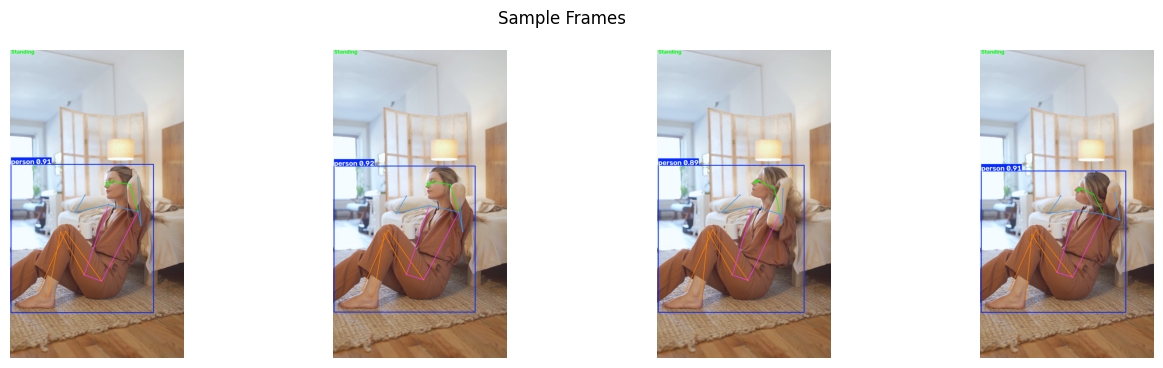

In [6]:
if not video_files:
  print("No Videos Found In The 'videos' Directory.")
else:
  Video_path = os.path.join('videos', video_files[0])

  print("Loading YOLOv8-Pose Model...")
  model = YOLO('yolov8n-pose.pt')
  print("YOLOv8-Pose Model Loaded Successfully")

  cap = cv2.VideoCapture(Video_path)
  fourcc = cv2.VideoWriter_fourcc(*'mp4v')
  out_path = 'pose_classification_output.mp4'
  fps = cap.get(cv2.CAP_PROP_FPS) or 15
  w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
  h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
  out = cv2.VideoWriter(out_path, fourcc, fps, (w, h))

  frame_idx = 0
  max_frames = 150
  sample_frames = []
  pose_history = []

  print(f"Processing Video: {video_files[0]}...")

  while True:
    ret, frame = cap.read()
    if not ret or frame_idx >= max_frames:
      break

    results = model(frame, verbose=False)
    label = "Unknown"

    if results[0].keypoints is not None and len(results[0].keypoints.xy) > 0:
      kpts = results[0].keypoints.xy[0]

      if len(kpts) > 14:
        shoulder_y = (kpts[5][1] + kpts[6][1]) / 2
        hip_y = (kpts[11][1] + kpts[12][1]) / 2
        knee_y = (kpts[13][1] + kpts[14][1]) / 2

        torso_len = abs(hip_y - shoulder_y) + 1e-5
        hip_knee_dist = abs(knee_y - hip_y)

        ratio = hip_knee_dist / torso_len

        if ratio < 0.45:
          label = "Sitting"
        elif ratio > 0.55:
          label = "Standing"

        frame = results[0].plot()

        color = (0, 255, 0) if label == "Standing" else (0, 165, 255) if label == "Sitting" else (0, 0, 255)
        cv2.putText(frame, label, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1.5, color, 3)

        out.write(frame)
        if frame_idx % 15 == 0:
          sample_frames.append(frame.copy())
          pose_history.append(label)
    frame_idx += 1

  cap.release()
  out.release()
  print(f"\n Processed {frame_idx} Frames -> {out_path}")
  print(f"Pose History (Every 15 Frames): {pose_history}")

  n = min(4, len(sample_frames))
  if n > 0:
    plt.figure(figsize=(16, 4))
    for i in range(n):
      plt.subplot(1, n, i + 1)
      plt.imshow(sample_frames[i][..., ::-1])
      plt.axis('off')
    plt.suptitle("Sample Frames")
    plt.show()